<img style="float: left; margin: 30px 15px 15px 15px;" src="https://oci02.img.iteso.mx/Identidades-De-Instancia/ITESO/Logos%20ITESO/Logo-ITESO-Principal.jpg" width="400" height="600" /> 

## <font color='navy'> Tarea 5. Regresión Lineal: Ingreso mensual en México (ENOE 2025-T1)
    
### <font color='navy'> Análisis Estadístico Multivariado
## <font color='black'> Mtro. Sean Nicolas Vázquez

## <font color='black'> Integrantes: Fernando Hernández y Luis Beltrán

### <font color='navy'> Parte 1. Unión de las tablas COE1, COE2 y SDEM.

La **Encuesta Nacional de Ocupación y Empleo (ENOE)** del INEGI publica cada trimestre varias tablas. Usamos tres:

| **Tabla** | **Contenido** |
|-----------|---------------|
| **COE1** | Cuestionario de Ocupación y Empleo, preguntas 1 a 5: condición de actividad, características del empleo (sindicato, contrato, prestaciones, tamaño de empresa) y jornada de trabajo. |
| **COE2** | Cuestionario de Ocupación y Empleo, preguntas 6 a 11: ingresos, segundo trabajo, búsqueda de empleo y uso del tiempo (capacitación, etc.). |
| **SDEM** | Características sociodemográficas (sexo, edad, escolaridad) y variables ya calculadas por el INEGI a partir del cuestionario, como el ingreso mensual (`ingocup`). |

COE1 y COE2 solo se aplican a la población de 12 años y más; SDEM incluye a todos los residentes de la vivienda. Las tres tablas tienen **un registro por persona** y comparten los mismos campos de identificación, por lo que se pueden unir.

Nuestras variables están repartidas en las tres tablas (`p3i`, `p3j`, `p3m*`, `p3q`, `p5c_thrs`, `p5e_thrs` en COE1; `p11_h1` en COE2; `ingocup`, `sex`, `anios_esc` en SDEM), así que en este notebook las unimos en un solo dataset.

In [167]:
# Cargar librerias
import pandas as pd
import numpy as np

#### Paso 1. Cargar los datos

Los CSV del INEGI guardan las respuestas vacías como un espacio en blanco (`' '`), así que las leemos como `NaN` con `na_values`.

In [168]:
# Rutas de los archivos
ruta = 'conjunto_de_datos_enoe_2025_1t_csv/'
ruta_coe1 = ruta + 'conjunto_de_datos_coe1_enoe_2025_1t/conjunto_de_datos/conjunto_de_datos_coe1_enoe_2025_1t.csv'
ruta_coe2 = ruta + 'conjunto_de_datos_coe2_enoe_2025_1t/conjunto_de_datos/conjunto_de_datos_coe2_enoe_2025_1t.csv'
ruta_sdem = ruta + 'conjunto_de_datos_sdem_enoe_2025_1t/conjunto_de_datos/conjunto_de_datos_sdem_enoe_2025_1t.csv'
#ruta_coe1 = 'ENOE_COE1T125.csv'
#ruta_coe2 = 'ENOE_COE2T125.csv'

In [169]:
# Cargar datos
coe1 = pd.read_csv(ruta_coe1, na_values=' ', low_memory=False)
coe2 = pd.read_csv(ruta_coe2, na_values=' ', low_memory=False)
sdem = pd.read_csv(ruta_sdem, na_values=' ', low_memory=False)

print('COE1:', coe1.shape)
print('COE2:', coe2.shape)
print('SDEM:', sdem.shape)

COE1: (345626, 189)
COE2: (345626, 137)
SDEM: (423302, 114)


In [170]:
coe1.head()

,r_def,cd_a,ent,con,upm,d_sem,n_pro_viv,v_sel,n_hog,h_mud,...,p5g13,p5g14,p5g15,p5g99,p5h,ur,tipo,mes_cal,fac_tri,fac_men
0,0,1,9,40002,905953,305,4,51,1,0,...,NaN,14.0,NaN,NaN,NaN,1,1,1,1286,4109
1,0,1,9,40002,905953,305,4,51,1,0,...,NaN,NaN,NaN,NaN,NaN,1,1,1,1286,4109
2,0,1,9,40009,917468,101,199,3,1,0,...,NaN,NaN,NaN,NaN,NaN,1,1,96,1518,0
3,0,1,9,40009,917468,101,199,3,1,0,...,NaN,14.0,NaN,NaN,NaN,1,1,96,1518,0
4,0,1,9,40014,911027,302,99,54,1,1,...,NaN,14.0,NaN,NaN,NaN,1,1,1,1247,3983


In [171]:
coe2.head()

,cd_a,ent,con,upm,d_sem,n_pro_viv,v_sel,n_hog,h_mud,n_ent,...,p11_h7,p11_m7,p11_8,p11_h8,p11_m8,ur,tipo,mes_cal,fac_tri,fac_men
0,1,9,40003,906619,101,77,4,1,0,5,...,35.0,0.0,NaN,NaN,NaN,1,1,96,464,0
1,1,9,40003,906619,101,77,4,1,0,5,...,35.0,0.0,NaN,NaN,NaN,1,1,96,464,0
2,1,9,40003,906619,101,77,4,1,0,5,...,NaN,NaN,NaN,NaN,NaN,1,1,96,464,0
3,1,9,40005,906533,310,168,53,1,0,3,...,10.0,0.0,NaN,NaN,NaN,1,1,3,1019,3336
4,1,9,40006,906681,309,42,52,1,0,3,...,35.0,0.0,NaN,NaN,NaN,1,1,2,798,2467


In [172]:
sdem.head()

,r_def,loc,mun,est,est_d_tri,est_d_men,ageb,t_loc_tri,t_loc_men,cd_a,...,scian,t_tra,emp_ppal,tue_ppal,trans_ppal,mh_fil2,mh_col,sec_ins,tipo,mes_cal
0,0,NaN,11.0,30,681,661.0,0,1,1.0,1,...,8,1,2,2,0,3,2,2,1,3
1,0,NaN,8.0,20,123,123.0,0,1,1.0,1,...,16,1,2,2,0,3,2,6,1,1
2,0,NaN,8.0,20,123,123.0,0,1,1.0,1,...,11,1,2,2,0,3,2,2,1,1
3,0,NaN,10.0,20,680,660.0,0,1,1.0,1,...,0,0,0,0,0,0,0,0,1,3
4,0,NaN,10.0,40,682,667.0,0,1,1.0,1,...,0,0,0,0,0,0,0,0,1,2


#### Paso 2. Definir la llave de unión

De acuerdo con el documento del INEGI *Conociendo la base de datos de la ENOE*, la llave para relacionar COE1, COE2 y SDEM está formada por:

| **Campo** | **Descripción** |
|-----------|-----------------|
| `cd_a` | Ciudad autorrepresentada |
| `ent` | Entidad |
| `con` | Control |
| `v_sel` | Vivienda seleccionada |
| `n_hog` | Número de hogar |
| `h_mud` | Hogar mudado |
| `n_ren` | Número de renglón (persona dentro del hogar) |

Sin embargo, ese documento es de la época en la que todas las entrevistas eran cara a cara. Desde la ENOE nueva se combinan entrevistas **cara a cara y telefónicas** (`tipo`) y se registra el **mes calendario** (`mes_cal`), por lo que la llave de 7 campos ya no identifica a una persona de forma única. Lo comprobamos:

In [173]:
# Llave documentada (ENOE 2010)
llave_2010 = ['cd_a', 'ent', 'con', 'v_sel', 'n_hog', 'h_mud', 'n_ren']

print('Duplicados en COE1:', coe1.duplicated(llave_2010).sum())
print('Duplicados en COE2:', coe2.duplicated(llave_2010).sum())
print('Duplicados en SDEM:', sdem.duplicated(llave_2010).sum())

Duplicados en COE1: 2674
Duplicados en COE2: 2674
Duplicados en SDEM: 3350


Si uniéramos con esta llave tendríamos una unión *muchos a muchos*: el número de registros crecería y se mezclarían personas distintas (por ejemplo, con edades diferentes en cada tabla). Agregando `tipo` y `mes_cal` la llave se vuelve única:

In [174]:
# Llave completa
llave = ['tipo', 'mes_cal', 'cd_a', 'ent', 'con', 'v_sel', 'n_hog', 'h_mud', 'n_ren']

print('Duplicados en COE1:', coe1.duplicated(llave).sum())
print('Duplicados en COE2:', coe2.duplicated(llave).sum())
print('Duplicados en SDEM:', sdem.duplicated(llave).sum())

Duplicados en COE1: 0
Duplicados en COE2: 0
Duplicados en SDEM: 0


#### Paso 3. Unir COE1 y COE2

Además de la llave, ambas tablas repiten algunas columnas de identificación (edad, UPM, ponderadores, etc.). Antes de unir verificamos que, para la misma persona, esas columnas coincidan. Si coinciden, solo conservamos la copia de COE1 para no duplicar columnas.

In [175]:
# Columnas que aparecen en ambas tablas pero no forman parte de la llave
comunes = [c for c in coe1.columns if c in coe2.columns and c not in llave]
comunes

['upm',
 'd_sem',
 'n_pro_viv',
 'n_ent',
 'per',
 'eda',
 'n_inf',
 'ur',
 'fac_tri',
 'fac_men']

In [176]:
# Unión de prueba con indicador para validar la correspondencia 1 a 1
prueba = coe1[llave + comunes].merge(coe2[llave + comunes], on=llave, how='outer',
                                     suffixes=('_coe1', '_coe2'), indicator=True)
print(prueba['_merge'].value_counts())

# Diferencias en las columnas comunes
diferencias = {c: (prueba[c + '_coe1'].fillna(-1) != prueba[c + '_coe2'].fillna(-1)).sum() for c in comunes}
pd.Series(diferencias, name='registros distintos')

_merge
both          345626
left_only          0
right_only         0
Name: count, dtype: int64


upm          0
d_sem        0
n_pro_viv    0
n_ent        0
per          0
eda          0
n_inf        0
ur           0
fac_tri      0
fac_men      0
Name: registros distintos, dtype: int64

Todos los registros están en ambas tablas (`both`) y las columnas comunes coinciden, así que hacemos la unión definitiva. Usamos `validate='one_to_one'` para que pandas marque error si la llave no fuera única.

In [177]:
# Unir COE1 con las columnas propias de COE2
coe = coe1.merge(coe2.drop(columns=comunes), on=llave, how='inner', validate='one_to_one')

print('COE1:', coe1.shape)
print('COE2:', coe2.shape)
print('COE :', coe.shape)

COE1: (345626, 189)
COE2: (345626, 137)
COE : (345626, 307)


In [178]:
coe.head()

,r_def,cd_a,ent,con,upm,d_sem,n_pro_viv,v_sel,n_hog,h_mud,...,p11_m5,p11_6,p11_h6,p11_m6,p11_7,p11_h7,p11_m7,p11_8,p11_h8,p11_m8
0,0,1,9,40002,905953,305,4,51,1,0,...,NaN,NaN,NaN,NaN,7.0,98.0,0.0,NaN,NaN,NaN
1,0,1,9,40002,905953,305,4,51,1,0,...,NaN,NaN,NaN,NaN,7.0,3.0,30.0,NaN,NaN,NaN
2,0,1,9,40009,917468,101,199,3,1,0,...,NaN,6.0,5.0,0.0,7.0,21.0,0.0,NaN,NaN,NaN
3,0,1,9,40009,917468,101,199,3,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1,9,40014,911027,302,99,54,1,1,...,NaN,NaN,NaN,NaN,7.0,98.0,0.0,NaN,NaN,NaN


#### Paso 4. Unir con SDEM

SDEM tiene más registros que COE porque incluye a todos los residentes de la vivienda (también a los menores de 12 años, a quienes no se les aplica el cuestionario). Igual que antes, primero revisamos que cada persona de `coe` tenga su registro en SDEM y que las columnas que se repiten coincidan.

In [179]:
# Columnas que aparecen en ambas tablas pero no forman parte de la llave
comunes_sdem = [c for c in sdem.columns if c in coe.columns and c not in llave]
print(comunes_sdem)

# Unión de prueba: todas las personas de coe deben estar en SDEM
prueba = coe[llave + comunes_sdem].merge(sdem[llave + comunes_sdem], on=llave, how='left',
                                         suffixes=('_coe', '_sdem'), indicator=True)
print(prueba['_merge'].value_counts())

# Diferencias en las columnas comunes
diferencias = {c: (prueba[c + '_coe'].fillna(-1) != prueba[c + '_sdem'].fillna(-1)).sum() for c in comunes_sdem}
pd.Series(diferencias, name='registros distintos')

['r_def', 'upm', 'd_sem', 'n_pro_viv', 'n_ent', 'per', 'eda', 'ur', 'fac_tri', 'fac_men']
_merge
both          345626
left_only          0
right_only         0
Name: count, dtype: int64


r_def        0
upm          0
d_sem        0
n_pro_viv    0
n_ent        0
per          0
eda          0
ur           0
fac_tri      0
fac_men      0
Name: registros distintos, dtype: int64

Las 345,626 personas de `coe` están en SDEM y las columnas comunes coinciden. Hacemos la unión con `how='inner'` para quedarnos solo con las personas que tienen cuestionario, y quitamos de SDEM las columnas repetidas.

In [180]:
# Unir coe con las columnas propias de SDEM
enoe = coe.merge(sdem.drop(columns=comunes_sdem), on=llave, how='inner', validate='one_to_one')

print('COE :', coe.shape)
print('SDEM:', sdem.shape)
print('ENOE:', enoe.shape)

COE : (345626, 307)
SDEM: (423302, 114)
ENOE: (345626, 402)


#### Paso 5. Verificar las variables de interés

Revisamos que las variables seleccionadas existan en el dataset unido. Algunos nombres del cuestionario cambian en la base de datos:

+ **11 opción 1** (capacitación) se guarda en `p11_1` (sí/no), `p11_h1` (horas) y `p11_m1` (minutos).
+ **3m** (prestaciones) es de respuesta múltiple: cada opción es una columna (`p3m1` a `p3m9`).

In [181]:
# Variables seleccionadas
variables = {
    'ingocup':   'Ingreso mensual (SDEM)',
    'p3i':       'Pertenece a sindicato',
    'p3j':       'Tiene contrato por escrito',
    'p3q':       'Tamaño de la empresa',
    'p3m1':      'Prestación: crédito vivienda',
    'p3m2':      'Prestación: guardería',
    'p3m3':      'Prestación: cuidados maternos/paternos',
    'p3m4':      'Prestación: fondo de retiro',
    'p3m5':      'Prestación: seguro de vida',
    'p3m6':      'Prestación: gastos médicos privados',
    'p3m7':      'Prestación: préstamos / caja de ahorro',
    'p5c_thrs':  'Horas trabajadas la semana pasada',
    'p5e_thrs':  'Horas trabajadas habitualmente',
    'p11_h1':    'Horas de capacitación',
    'p11_m1':    'Minutos de capacitación',
    'eda':       'Edad',
    'sex':       'Sexo (SDEM)',
    'anios_esc': 'Años de escolaridad (SDEM)',
}

pd.DataFrame({'descripcion': variables.values(),
              'existe': [v in enoe.columns for v in variables],
              'no_nulos': [enoe[v].notna().sum() if v in enoe.columns else 0 for v in variables]},
             index=variables.keys())

,descripcion,existe,no_nulos
ingocup,Ingreso mensual (SDEM),True,345626
p3i,Pertenece a sindicato,True,135571
p3j,Tiene contrato por escrito,True,135571
p3q,Tamaño de la empresa,True,141701
p3m1,Prestación: crédito vivienda,True,68672
p3m2,Prestación: guardería,True,27814
p3m3,Prestación: cuidados maternos/paternos,True,32234
p3m4,Prestación: fondo de retiro,True,67115
p3m5,Prestación: seguro de vida,True,33366
p3m6,Prestación: gastos médicos privados,True,7853


#### Paso 6. Guardar el dataset unido

In [182]:
# Guardar en CSV
enoe.to_csv('enoe_2025_1t_coe_sdem.csv', index=False)

### <font color='navy'> Parte 2. Variable objetivo: ingreso mensual (`ingocup`)

#### Paso 1. ¿Qué es `ingocup`?

`ingocup` es el **ingreso mensual del trabajo principal**, ya calculado por el INEGI en SDEM. Según el documento *Reconstrucción de variables de la ENOE*, se toma directamente de la pregunta 6b2 del cuestionario, que ya viene convertida a pesos mensuales sin importar cada cuándo le pagan a la persona. Por eso no hay que hacerle ninguna transformación.

Cuando la persona no recibe ingresos, no trabaja o no supo o no quiso decir cuánto gana, `ingocup` vale **0**. Lo comprobamos comparándola con `p6b2`:

In [183]:
# ingocup es igual a p6b2, con 0 donde p6b2 está vacía
print('Coincide con p6b2:', (enoe['ingocup'] == enoe['p6b2'].fillna(0)).mean() * 100, '%')
print('Registros con ingocup = 0:', (enoe['ingocup'] == 0).sum())

Coincide con p6b2: 100.0 %
Registros con ingocup = 0: 225929


#### Paso 2. Filtrar los registros

Trabajamos sobre una copia filtrada (`df`); `enoe` no se modifica.

1. **Edad de 15 a 97 años**, criterio oficial del INEGI para la población de 15 años y más.
2. **Ingreso mensual de 1 a 999,998 pesos** (rango válido de `ingocup`). Con esto se eliminan quienes no trabajan, los trabajadores sin pago y quienes no especificaron su ingreso.

In [184]:
print('Registros iniciales:   ', len(enoe))

# 1. Población de 15 a 97 años
df = enoe[enoe['eda'].between(15, 97)].copy()
print('1. Edad 15 a 97 años:  ', len(df))

# 2. Ingreso mensual válido
df = df[df['ingocup'].between(1, 999998)]
print('2. Con ingreso mensual:', len(df))

Registros iniciales:    345626
1. Edad 15 a 97 años:   323806
2. Con ingreso mensual: 119137


#### Paso 3. Construir la variable objetivo

La variable objetivo es `ingocup` tal cual (ingreso mensual en pesos); la llamamos `ingreso_mensual`.

> **Nota:** más adelante se podría modelar el logaritmo del ingreso. Con el log, los coeficientes se interpretan como cambios porcentuales (por ejemplo, "tener contrato se asocia con ≈ 20% más de ingreso") y la distribución queda más simétrica.

In [185]:
# Variable objetivo
df = df.assign(ingreso_mensual=df['ingocup'])

df['ingreso_mensual'].describe(percentiles=[.01, .10, .25, .50, .75, .90, .99]).round(0)

count    119137.0
mean      10528.0
std        8646.0
min           1.0
1%          645.0
10%        3010.0
25%        6020.0
50%        8600.0
75%       12900.0
90%       18060.0
99%       43000.0
max      245000.0
Name: ingreso_mensual, dtype: float64

#### Paso 4. Distribución del ingreso mensual

El ingreso está muy sesgado a la derecha: la mayoría gana poco y unos cuantos ganan muchísimo, lo que produce una cola larga.

> **Muestra vs. población (`fac_tri`):** la ENOE no entrevista a todo México, sino a una muestra. Cada persona entrevistada representa a otras personas parecidas a ella, y cuántas representa lo indica el **factor de expansión trimestral `fac_tri`**. En la gráfica contamos cada registro una vez, así que el eje *y* es el número de personas **en la muestra** (119,137). Si en lugar de contar registros sumamos `fac_tri`, obtenemos la **población** que representan: unos 34.8 millones de trabajadores en México. Para la regresión trabajamos con la muestra; `fac_tri` lo usaremos en el reporte para hablar de millones de personas.

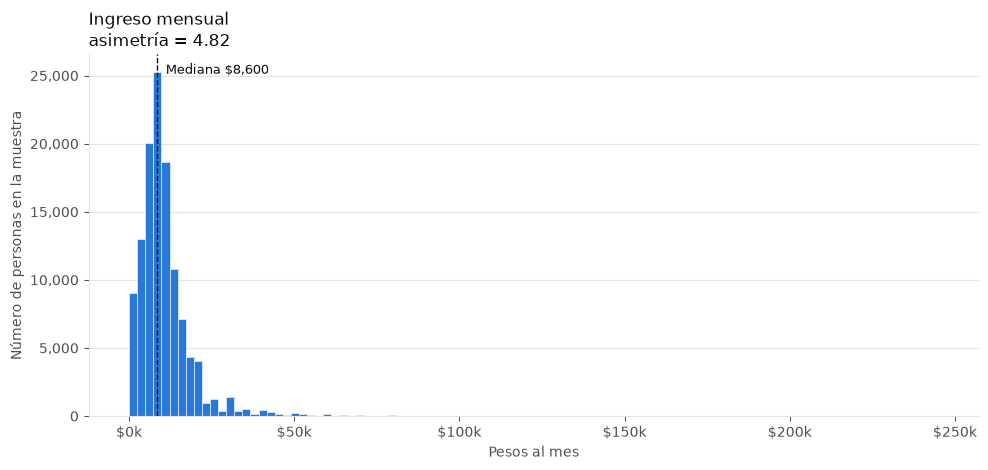

In [186]:
import matplotlib.pyplot as plt

# Colores
azul, texto, texto_2, grid = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df'

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(df['ingreso_mensual'], bins=100, color=azul, edgecolor='white', linewidth=0.4)

# Mediana como referencia
mediana = df['ingreso_mensual'].median()
ax.axvline(mediana, color=texto, linewidth=1, linestyle='--')
ax.annotate(f'Mediana ${mediana:,.0f}', xy=(mediana, 1), xycoords=('data', 'axes fraction'),
            xytext=(6, -14), textcoords='offset points', color=texto, fontsize=9)

ax.set_title(f"Ingreso mensual\nasimetría = {df['ingreso_mensual'].skew():.2f}", loc='left', color=texto, fontsize=12)
ax.set_xlabel('Pesos al mes', color=texto_2)
ax.set_ylabel('Número de personas en la muestra', color=texto_2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x / 1000:,.0f}k'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:,.0f}'))
ax.grid(axis='y', color=grid, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=texto_2)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']:
    ax.spines[lado].set_color(grid)

plt.tight_layout()
plt.show()

### <font color='navy'> Parte 3. Variables explicativas

#### Paso 1. Solo trabajadores subordinados con pago (`p3h`)

Las preguntas de sindicato (3i), contrato (3j) y prestaciones (3l y 3m) **solo se les hacen a los trabajadores subordinados**, es decir, a quienes tienen un jefe. A quienes trabajan por su cuenta el cuestionario se las salta, y tampoco tienen tamaño de empresa (`p3q`). Además, es difícil medir el salario de alguien que es su propio jefe.

La pregunta 3h (*"¿En este trabajo ... recibe un pago?"*) solo la contestan los subordinados, y `p3h = 1` significa que reciben un pago. Por eso nos quedamos únicamente con los registros con `p3h = 1`; los independientes quedan fuera porque no tienen respuesta en esta pregunta.

In [187]:
# Solo trabajadores subordinados que reciben un pago
df = df[df['p3h'] == 1]
print('Subordinados con pago:', len(df))

Subordinados con pago: 89975


#### Paso 2. Sindicato (`p3i`), contrato (`p3j`) y tamaño de empresa (`p3q`)

+ **Sindicato:** 1 = pertenece a un sindicato, 0 = no.
+ **Contrato:** 1 = tiene contrato por escrito (temporal o de base), 0 = no.
+ **Tamaño de empresa:** ordinal de 1 (1 persona) a 11 (501 y más personas). El modelo la tratará como numérica, es decir, asume la misma distancia entre categorías consecutivas.

Eliminamos los "no sabe": 9 en `p3i` y `p3j`, y 99 en `p3q`.

In [188]:
# Quitar "no sabe": 9 en sindicato y contrato, 99 en tamaño de empresa
df = df[(df['p3i'] != 9) & (df['p3j'] != 9) & (df['p3q'] != 99)]

# Binarias: 1 = sí, 0 = no
df = df.assign(sindicato=(df['p3i'] == 1).astype(int),
               contrato=(df['p3j'] == 1).astype(int),
               tamano_empresa=df['p3q'].astype(int))

print('Sin "no sabe" en sindicato, contrato y tamaño:', len(df))
df[['sindicato', 'contrato']].mean().round(3)

Sin "no sabe" en sindicato, contrato y tamaño: 82880


sindicato    0.156
contrato     0.543
dtype: float64

#### Paso 3. Prestaciones (`p3m1` a `p3m9`)

La pregunta 3m es de respuesta múltiple: cada opción (crédito de vivienda, guardería, cuidados maternos/paternos, fondo de retiro, seguro de vida, gastos médicos, préstamos) es una columna. Por simplicidad la reducimos a una **binaria**: si tiene al menos una prestación o no, sin importar cuántas tenga.

Hay que cuidar los vacíos: cuando a la persona **no le dan nada** en la pregunta anterior (3l: ni aguinaldo, ni vacaciones, ni utilidades, `p3l5`), el cuestionario se salta la 3m. Esos vacíos no son "no sabe", sino personas sin prestaciones, así que valen **0**. Solo eliminamos los "no sabe" (`p3m9` o `p3l9`).

In [189]:
# Quitar "no sabe" (p3m9 o p3l9)
df = df[df['p3m9'].isna() & df['p3l9'].isna()]

# 1 si marcó al menos una prestación de 3m (opciones 1 a 7);
# 0 si marcó "ninguna de las anteriores" (p3m8) o "no le dan nada" en 3l (p3l5)
df = df.assign(prestaciones=df[[f'p3m{i}' for i in range(1, 8)]].notna().any(axis=1).astype(int))

print('Sin "no sabe" en prestaciones:', len(df))
df['prestaciones'].value_counts()

Sin "no sabe" en prestaciones: 82129


prestaciones
1    42976
0    39153
Name: count, dtype: int64

#### Paso 4. Horas de capacitación (`p11_h1`, `p11_m1`)

La pregunta 11 opción 1 registra cuánto tiempo dedicó la persona la semana pasada a *"estudiar o tomar cursos de capacitación (incluye el tiempo dedicado a realizar trabajos escolares)"*. Sumamos horas y minutos (`p11_h1 + p11_m1 / 60`).

+ Si está vacía, la persona no realizó esa actividad, así que le asignamos **0 horas**.
+ Los valores 98 y 99 se concentran en un pico sin minutos, por lo que los tratamos como no especificado y los eliminamos.

> **Nota:** la pregunta incluye estudiar en general, no solo capacitación para el trabajo. Quienes la reportan son sobre todo personas jóvenes que estudian y trabajan, así que el efecto sobre el ingreso podría no ser positivo.

In [190]:
# Quitar 98 y 99 (no especificado)
df = df[~df['p11_h1'].isin([98, 99])]

# Horas + minutos; vacío = no estudió ni tomó cursos -> 0 horas
df = df.assign(horas_capacitacion=(df['p11_h1'] + df['p11_m1'] / 60).fillna(0))

print('Con horas de capacitación válidas:', len(df))
print('Personas con más de 0 horas:      ', (df['horas_capacitacion'] > 0).sum())

Con horas de capacitación válidas: 82020
Personas con más de 0 horas:       6373


#### Paso 5. Edad (`eda`) y sexo (`sex`)

+ **Edad:** años cumplidos. Ya está filtrada de 15 a 97 años en la Parte 2. No entra directamente al modelo, pero la usamos para calcular la experiencia (Paso 8).
+ **Sexo:** en SDEM, 1 = hombre y 2 = mujer. La convertimos en la binaria `mujer` (1 = mujer, 0 = hombre).

In [191]:
# Binaria: 1 = mujer, 0 = hombre
df = df.assign(mujer=(df['sex'] == 2).astype(int))

print('Proporción de mujeres:', round(df['mujer'].mean(), 3))
df['eda'].describe().round(1)

Proporción de mujeres: 0.428


count    82020.0
mean        38.2
std         13.4
min         15.0
25%         27.0
50%         37.0
75%         48.0
max         97.0
Name: eda, dtype: float64

#### Paso 6. Horas trabajadas a la semana (`p5c_thrs`, `p5e_thrs`)

SDEM trae la variable `hrsocup`, pero son solo las horas trabajadas **la semana pasada** (coincide con `p5c_thrs`). Quienes tienen trabajo pero estuvieron ausentes esa semana (vacaciones, incapacidad, etc.) aparecen con 0 horas, aunque sí trabajen. Si los elimináramos perderíamos unos 3 mil trabajadores, y además con ingreso más alto que el resto (suelen ser empleos formales con vacaciones o incapacidad pagadas), lo que sesgaría la muestra. Por eso usamos las preguntas del cuestionario:

+ La pregunta 5c registra las horas trabajadas la semana pasada (`p5c_thrs`).
+ La 5e registra las horas que trabaja **habitualmente** (`p5e_thrs`). Se le pregunta a quien no trabajó la semana pasada y a quien dice (en la 5d) que esas no son sus horas habituales.

Así que:

+ Si `p5e_thrs` tiene dato, usamos las horas habituales.
+ Si no, usamos `p5c_thrs`: la semana pasada fue su semana habitual.

Con esto `horas_semana` son las horas que la persona trabaja **normalmente**, que es lo que corresponde con un ingreso mensual. Eliminamos los registros sin ninguno de los dos datos y los que tienen 999 (no especificado).

In [192]:
# Horas habituales si las dio (p5e_thrs); si no, las de la semana pasada (p5c_thrs)
df = df.assign(horas_semana=df['p5e_thrs'].fillna(df['p5c_thrs']))

# Quitar sin dato y "no especificado" (999)
df = df[df['horas_semana'].notna() & (df['horas_semana'] != 999)]

print('Con horas a la semana válidas:', len(df))
df['horas_semana'].describe().round(1)

Con horas a la semana válidas: 81508


count    81508.0
mean        43.2
std         14.7
min          1.0
25%         37.0
50%         45.0
75%         48.0
max        140.0
Name: horas_semana, dtype: float64

#### Paso 7. Años de escolaridad (`anios_esc`)

Años de estudio aprobados, de 0 a 24. Eliminamos el 99 (no especificado).

In [193]:
# Quitar "no especificado" (99)
df = df[df['anios_esc'] != 99]

print('Con escolaridad válida:', len(df))
df['anios_esc'].describe().round(1)

Con escolaridad válida: 81360


count    81360.0
mean        11.0
std          4.1
min          0.0
25%          9.0
50%         11.0
75%         14.0
max         23.0
Name: anios_esc, dtype: float64

#### Paso 8. Experiencia potencial (ecuación de Mincer)

La ENOE no pregunta cuántos años ha trabajado una persona en total. En su lugar usamos la **experiencia potencial** de la ecuación de Mincer: los años que la persona pudo haber trabajado desde que terminó de estudiar, suponiendo que empezó la escuela a los 6 años.

$$\text{experiencia} = \text{edad} - \text{años de escolaridad} - 6$$

+ Es una aproximación: no descuenta los años en que la persona no trabajó.
+ Unos cuantos registros dan negativo (por ejemplo, alguien de 20 años con 16 de escolaridad); les asignamos 0.

> **Ojo con la multicolinealidad:** `experiencia` se calcula con `eda` y `anios_esc`, así que las tres variables están casi perfectamente relacionadas (solo difieren en los registros que llevamos a 0). Si las tres entran juntas a la regresión, el modelo no puede separar el efecto de cada una y los coeficientes salen inestables. Por eso **quitamos `eda`** del modelo y dejamos `anios_esc` y `experiencia`, como en la ecuación de Mincer.

In [194]:
# Experiencia potencial; los negativos valen 0
experiencia = df['eda'] - df['anios_esc'] - 6
print('Registros con experiencia negativa:', (experiencia < 0).sum())

df = df.assign(experiencia=experiencia.clip(lower=0))
df['experiencia'].describe().round(1)

Registros con experiencia negativa: 181


count    81360.0
mean        21.2
std         14.7
min          0.0
25%          9.0
50%         19.0
75%         32.0
max         84.0
Name: experiencia, dtype: float64

#### Paso 9. Dataset para el modelo

Nos quedamos con la variable objetivo y las nueve variables explicativas. La edad (`eda`) no entra porque ya está contenida en la experiencia (ver Paso 8). También conservamos `fac_tri` para poder expresar resultados en millones de personas en el reporte; no entra en la regresión.

In [195]:
# Dataset para el modelo
columnas = ['ingreso_mensual', 'sindicato', 'contrato', 'tamano_empresa', 'prestaciones', 'horas_capacitacion',
            'mujer', 'horas_semana', 'anios_esc', 'experiencia', 'fac_tri']
modelo = df[columnas]

print('Dataset del modelo:', modelo.shape)
modelo.describe().round(2).T

Dataset del modelo: (81360, 11)


,count,mean,std,min,25%,50%,75%,max
ingreso_mensual,81360.0,10775.97,7918.15,1.0,6450.0,9000.0,12900.0,238000.0
sindicato,81360.0,0.16,0.36,0.0,0.0,0.0,0.0,1.0
contrato,81360.0,0.54,0.50,0.0,0.0,1.0,1.0,1.0
tamano_empresa,81360.0,5.43,3.59,1.0,2.0,4.0,9.0,11.0
prestaciones,81360.0,0.52,0.50,0.0,0.0,1.0,1.0,1.0
horas_capacitacion,81360.0,1.29,6.09,0.0,0.0,0.0,0.0,90.0
mujer,81360.0,0.43,0.49,0.0,0.0,0.0,1.0,1.0
horas_semana,81360.0,43.23,14.71,1.0,37.0,45.0,48.0,140.0
anios_esc,81360.0,10.96,4.11,0.0,9.0,11.0,14.0,23.0
experiencia,81360.0,21.19,14.66,0.0,9.0,19.0,32.0,84.0


#### Paso 10. Matriz de correlación de Pearson

Antes de ajustar el modelo revisamos qué tan relacionada está cada variable explicativa con el ingreso y entre sí. Una correlación alta entre dos X indica posible **multicolinealidad**: el modelo tiene problemas para separar el efecto de cada una.

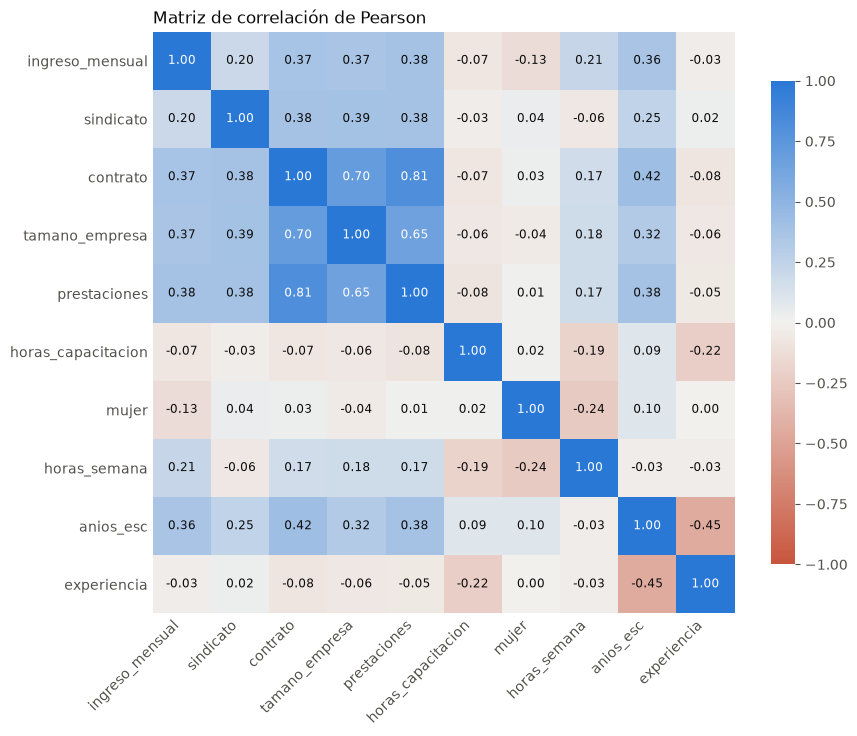

In [196]:
from matplotlib.colors import LinearSegmentedColormap

# Correlación de Pearson (sin fac_tri, que no entra al modelo)
correlacion = modelo.drop(columns='fac_tri').corr(method='pearson')

# Escala divergente: naranja (negativa) - gris (0) - azul (positiva)
divergente = LinearSegmentedColormap.from_list('divergente', ['#c8553d', '#f2f1ee', azul])

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(correlacion, cmap=divergente, vmin=-1, vmax=1)

# Valor de cada celda
for i in range(len(correlacion)):
    for j in range(len(correlacion)):
        valor = correlacion.iloc[i, j]
        ax.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=8.5,
                color='white' if abs(valor) >= 0.6 else texto)

ax.set_xticks(range(len(correlacion)), correlacion.columns, rotation=45, ha='right')
ax.set_yticks(range(len(correlacion)), correlacion.columns)
ax.tick_params(colors=texto_2, length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title('Matriz de correlación de Pearson', loc='left', color=texto, fontsize=12)

barra = fig.colorbar(im, ax=ax, shrink=0.8)
barra.ax.tick_params(colors=texto_2)
barra.outline.set_visible(False)

plt.tight_layout()
plt.show()

**Lo más importante de la matriz:**

1. **Ninguna variable por sí sola explica gran parte del ingreso.** Las correlaciones más altas con `ingreso_mensual` son moderadas (≈ 0.36 a 0.38): `prestaciones`, `contrato`, `tamano_empresa` y `anios_esc`. Le siguen `horas_semana` (0.21) y `sindicato` (0.20). Esto es consistente con un R² de alrededor de 0.27: el ingreso depende de muchas cosas que no medimos.
2. **Las variables de formalidad están muy relacionadas entre sí.** `contrato` y `prestaciones` tienen 0.81, y las dos tienen ≈ 0.65 a 0.70 con `tamano_empresa`. Las tres miden casi lo mismo: un empleo formal en una empresa grande. Por eso, en la regresión, el efecto de `contrato` se reduce mucho: su relación con el ingreso ya la "absorben" `prestaciones` y `tamano_empresa`. Aun así, ninguna pasa de 0.9, así que pueden convivir en el modelo.
3. **La experiencia casi no se correlaciona con el ingreso (−0.03), pero eso no significa que no importe.** Tiene correlación de −0.45 con `anios_esc`: las personas con más experiencia suelen ser mayores y haber estudiado menos años. Ese efecto se cancela en la correlación simple; en la regresión, al controlar por escolaridad, la experiencia sí aparece positiva y significativa.
4. **`mujer` tiene una correlación negativa con el ingreso (−0.13) y con `horas_semana` (−0.24):** las mujeres de la muestra trabajan menos horas remuneradas, lo que explica parte (pero no toda) la brecha de ingreso.
5. **`horas_capacitacion` tiene una correlación débil y negativa (−0.07)** y se relaciona negativamente con la experiencia (−0.22): quienes estudian o toman cursos son sobre todo jóvenes con poca experiencia, como anticipamos en el Paso 4.

### <font color='navy'> Parte 4. Aplicando modelo de Regresión Lineal Múltiple.

In [197]:
# Cargar libreria adicional
import statsmodels.api as sm

In [198]:
# definir variables
y = modelo['ingreso_mensual']
x = modelo.drop(['ingreso_mensual','fac_tri'], axis=1)

# añadir constante
x = sm.add_constant(x)

#fit 
model = sm.OLS(y, x).fit()

# Resumen
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        ingreso_mensual   R-squared:                       0.274
Model:                            OLS   Adj. R-squared:                  0.273
Method:                 Least Squares   F-statistic:                     3404.
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:27:24   Log-Likelihood:            -8.3280e+05
No. Observations:               81360   AIC:                         1.666e+06
Df Residuals:                   81350   BIC:                         1.666e+06
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -3294.4096    133

### <font color='navy'> Parte 5. Analizando el summary del modelo.

**Ajuste general**

Tenemos un R² de 0.274. Al tener una regresión múltiple nos fijamos en el R² ajustado, que vale 0.273. Esto implica que:

1. La penalización por usar nueve variables es mínima (0.274 vs. 0.273): con más de 81 mil registros, agregar variables casi no "castiga" el R².
2. El modelo explica el **27.3% de la variabilidad del ingreso mensual**. El resto depende de factores que no estamos midiendo (ocupación, sector, región, etc.).
3. El estadístico F (3,404, p ≈ 0) indica que el modelo en conjunto es significativo: al menos una de las variables explica el ingreso.

Para comparar con modelos alternativos registramos AIC = 1.666e+06 y BIC = 1.666e+06.

**Significancia de los coeficientes**

Todas las variables tienen p-value menor a 0.05 (la más alta es `contrato`, con 0.009), así que todas son estadísticamente significativas y no hace falta quitar ninguna con selección backward. Con una muestra tan grande, hasta efectos pequeños salen significativos; por eso en la Parte 6 comparamos el tamaño de cada efecto con coeficientes estandarizados.

**Interpretación de cada coeficiente** (manteniendo las demás variables constantes)

| Variable | Coeficiente | Interpretación |
|---|---|---|
| `const` | −3,294 | Sería el ingreso de alguien con 0 en todas las variables (0 años de escolaridad, 0 horas trabajadas, etc.). Esa persona no existe en la muestra, así que no tiene interpretación práctica; solo ajusta el nivel de la recta. |
| `sindicato` | +472 | Pertenecer a un sindicato se asocia con \$472 más al mes. |
| `contrato` | +234 | Tener contrato por escrito se asocia con \$234 más al mes. Es mucho menos de lo que esperaríamos porque `contrato` está muy correlacionado con `prestaciones` (0.81) y `tamano_empresa` (0.70), que ya capturan casi todo el efecto de tener un empleo formal. |
| `tamano_empresa` | +303 | Cada categoría más de tamaño de empresa se asocia con \$303 más al mes. Las categorías son: 1 = 1 persona, 2 = 2 a 5, 3 = 6 a 10, 4 = 11 a 15, 5 = 16 a 20, 6 = 21 a 30, 7 = 31 a 50, 8 = 51 a 100, 9 = 101 a 250, 10 = 251 a 500 y 11 = 501 y más. Pasar de una empresa de 1 persona a una de más de 500 equivale a unos \$3,000 más al mes. |
| `prestaciones` | +1,934 | Tener al menos una prestación se asocia con \$1,934 más al mes. |
| `horas_capacitacion` | −27 | Cada hora a la semana dedicada a estudiar o capacitarse se asocia con \$27 menos al mes. No significa que capacitarse baje el sueldo: quienes reportan esas horas son sobre todo jóvenes que estudian y trabajan, con empleos de menor ingreso. |
| `mujer` | −2,000 | A igualdad de escolaridad, experiencia, horas, tipo de empleo y tamaño de empresa, las mujeres ganan \$2,000 menos al mes que los hombres (brecha salarial de género). |
| `horas_semana` | +78 | Cada hora adicional trabajada a la semana se asocia con \$78 más al mes. |
| `anios_esc` | +654 | Cada año adicional de escolaridad se asocia con \$654 más al mes. Por ejemplo, terminar la licenciatura (16 años) frente a solo la secundaria (9 años) equivale a unos \$4,600 más al mes. |
| `experiencia` | +73 | Cada año adicional de experiencia potencial se asocia con \$73 más al mes. |

**Supuestos**

+ El número de condición (295) es bajo, así que no hay un problema grave de multicolinealidad, aunque `contrato`, `prestaciones` y `tamano_empresa` estén correlacionadas.
+ El Durbin-Watson (1.77) es cercano a 2: no hay autocorrelación importante en los residuales.
+ Los residuales **no son normales**: la asimetría (5.08), la curtosis (67.4) y la prueba Jarque-Bera (p ≈ 0) lo confirman. Esto se debe a la cola larga del ingreso (unos pocos ganan muchísimo), como se ve en las gráficas de abajo. Modelar el logaritmo del ingreso ayudaría a corregirlo.

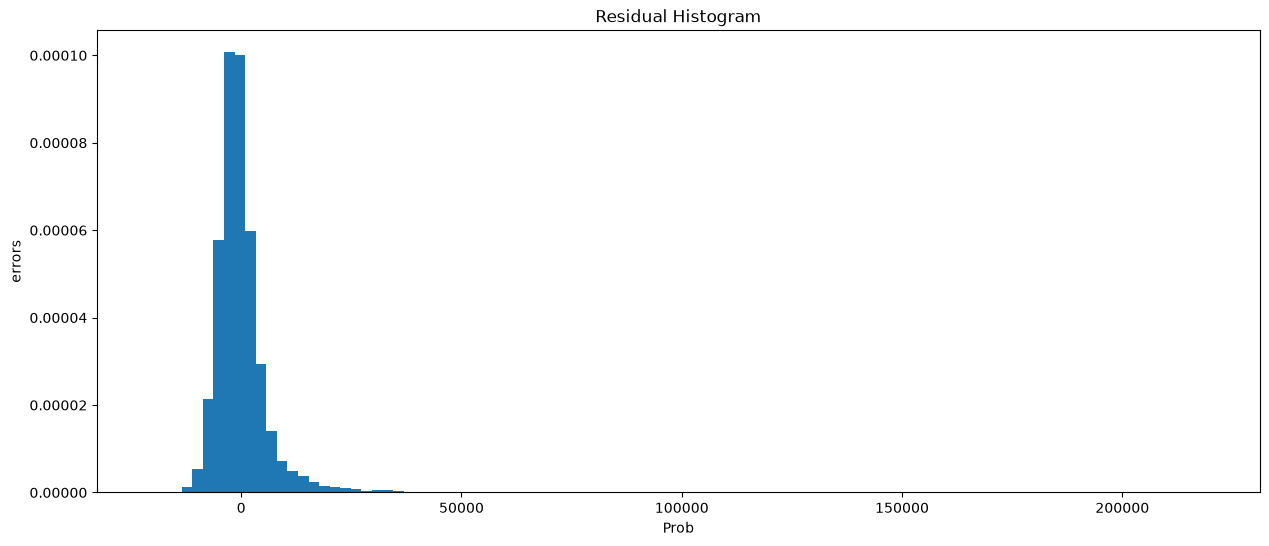

In [199]:
# Predecir con el modelo con coeficientes optimizados
y_hat=model.predict(x)
# Calcular lor residuales (errores)
residuals=y-y_hat
# Distribucion de residuales
plt.figure(figsize=(15, 6))
plt.hist(residuals, bins=100, density=True)
plt.xlabel("Prob")
plt.ylabel("errors")
plt.title("Residual Histogram")
plt.show();

<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:7: SyntaxWarning: invalid escape sequence '\h'
/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_78109/1983731073.py:4: SyntaxWarning: invalid escape sequence '\p'
  plt.axhline(np.std(residuals) * -2, label="$\pm 2 \sigma^2$", color='red', linestyle='--')
/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_78109/1983731073.py:7: SyntaxWarning: invalid escape sequence '\h'
  plt.xlabel("$\hat{y}$")


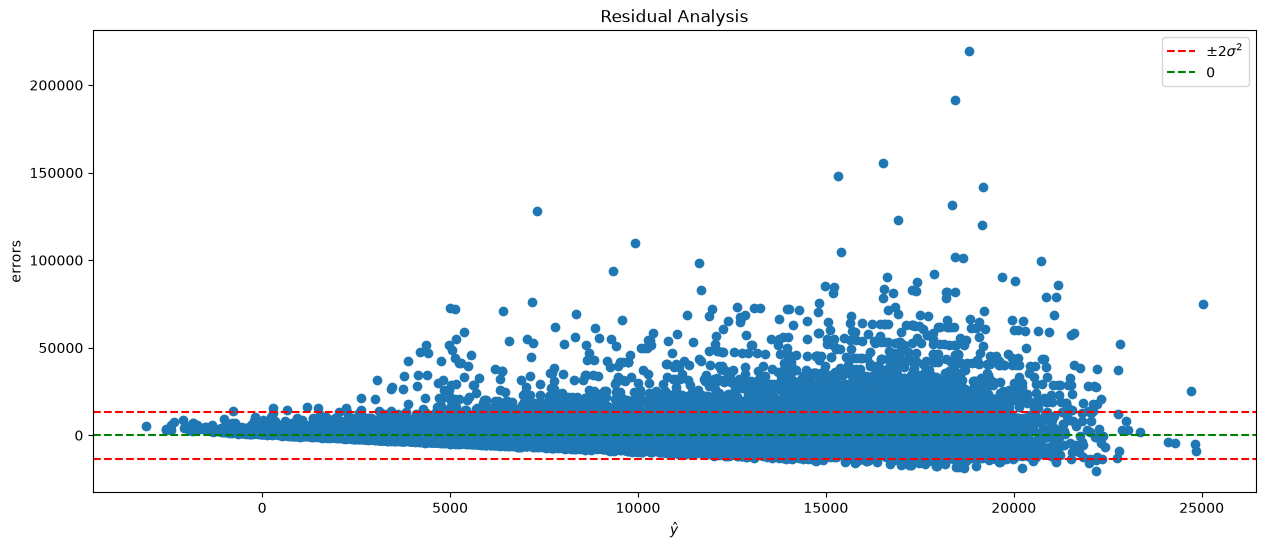

In [200]:
# Análisis residual
plt.figure(figsize=(15, 6))
plt.scatter(y_hat, residuals)
plt.axhline(np.std(residuals) * -2, label="$\pm 2 \sigma^2$", color='red', linestyle='--')
plt.axhline(0, linestyle='--', label="0", color="green")
plt.axhline(np.std(residuals) * 2, color='red', linestyle='--')
plt.xlabel("$\hat{y}$")
plt.ylabel("errors")
plt.title("Residual Analysis")
plt.legend()
plt.show();

### <font color='navy'> Parte 6. Coeficientes estandarizados

Los coeficientes del modelo están en las unidades de cada variable (pesos por año de escolaridad, pesos por hora trabajada, etc.), así que no se pueden comparar entre sí para saber cuál variable pesa más. Para eso **estandarizamos** todas las variables (les restamos la media y las dividimos entre su desviación estándar) y volvemos a ajustar el modelo con las nueve variables explicativas.

Cada coeficiente estandarizado indica **cuántas desviaciones estándar cambia el ingreso cuando la variable aumenta una desviación estándar**, manteniendo las demás constantes. Cuanto más lejos de 0, más importante es la variable.

In [201]:
# Estandarizar: (x - media) / desviación estándar
estandar = modelo.drop(columns='fac_tri')
estandar = (estandar - estandar.mean()) / estandar.std()

# Modelo con las variables estandarizadas (no hace falta constante: todas tienen media 0)
modelo_std = sm.OLS(estandar['ingreso_mensual'], estandar.drop(columns='ingreso_mensual')).fit()
coef_std = modelo_std.params.sort_values()
coef_std.round(3)

mujer                -0.125
horas_capacitacion   -0.021
contrato              0.015
sindicato             0.022
prestaciones          0.122
experiencia           0.136
tamano_empresa        0.137
horas_semana          0.145
anios_esc             0.339
dtype: float64

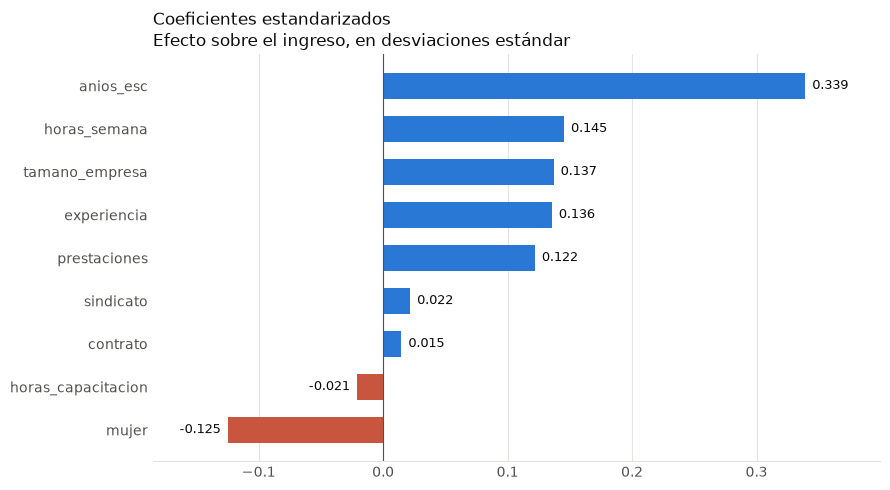

In [202]:
naranja = '#c8553d'

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coef_std.index, coef_std, color=[azul if v > 0 else naranja for v in coef_std], height=0.6)

# Valor al final de cada barra
for i, v in enumerate(coef_std):
    ax.annotate(f'{v:.3f}', xy=(v, i), xytext=(5 if v > 0 else -5, 0), textcoords='offset points',
                ha='left' if v > 0 else 'right', va='center', color=texto, fontsize=9)

ax.axvline(0, color=texto_2, linewidth=0.8)
ax.set_title('Coeficientes estandarizados\nEfecto sobre el ingreso, en desviaciones estándar',
             loc='left', color=texto, fontsize=12)
ax.set_xlim(coef_std.min() - 0.06, coef_std.max() + 0.06)
ax.grid(axis='x', color=grid, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=texto_2, length=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(grid)

plt.tight_layout()
plt.show()

**Lo más importante de la gráfica:**

1. **La escolaridad es, por mucho, la variable más importante** (0.34): más del doble que cualquier otra. Es la variable clásica de la ecuación de Mincer y la que más aportó al R² cuando la agregamos.
2. **Un segundo grupo con peso parecido (≈ 0.12 a 0.15):** `horas_semana`, `tamano_empresa`, `experiencia` y `prestaciones`, todas con efecto positivo.
3. **Ser mujer tiene un efecto negativo de tamaño similar a ese segundo grupo (−0.125).** Aun comparando personas con la misma escolaridad, experiencia, horas, tipo de empleo y tamaño de empresa, las mujeres ganan menos: es una medida de la brecha salarial de género.
4. **`contrato` y `sindicato` casi no pesan (≈ 0.02)** una vez que controlamos por las demás variables, aunque salgan significativos. En el caso de `contrato`, su efecto ya lo explican `prestaciones` y `tamano_empresa`, con las que está muy correlacionado (ver la matriz de correlación).
5. **`horas_capacitacion` tiene un efecto pequeño y negativo (−0.02).** Como vimos, refleja más a jóvenes que estudian y trabajan que una capacitación que aumente el salario.

> **Nota:** con más de 80 mil registros, hasta efectos muy pequeños salen estadísticamente significativos. Por eso conviene fijarse en el **tamaño** del coeficiente estandarizado y no solo en el p-value.